> **Estado de validación:** Modelo del profesor evaluado en validación y test completos de logística; métricas reales guardadas.

# Evaluación del modelo de logística suministrado

Se conserva `best.pt` del repositorio del profesor. Se descargan completas las particiones de validación y prueba de la versión 2, sin usar sus imágenes de entrenamiento. Esto evalúa el modelo suministrado; no demuestra que estas imágenes fueran desconocidas durante su entrenamiento original.

In [1]:
from ultralytics import YOLO
from IPython.display import display, Image
from pathlib import Path
import json, torch
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

In [2]:
from dotenv import load_dotenv
import os

load_dotenv(Path("..").resolve() / "apikeys.env")                 # reads ./.env by default
ROBOFLOW_API_KEY = os.getenv("ROBOFLOW_API_KEY")
if not ROBOFLOW_API_KEY:
    raise RuntimeError("Configura ROBOFLOW_API_KEY en apikeys.env antes de descargar los datos")
print("Credencial configurada:", bool(ROBOFLOW_API_KEY))

Credencial configurada: True


In [3]:
from download_eval_dataset import download_evaluation_dataset
from types import SimpleNamespace

In [4]:
!pwd

/Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment


In [5]:
dataset = SimpleNamespace(location=str(Path(download_evaluation_dataset(ROBOFLOW_API_KEY, "datasets/logistics_eval")).resolve()))
print("Datos:", dataset.location)

Datos: /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/datasets/logistics_eval


In [6]:
model = YOLO("best.pt")

In [7]:
metrics = model.val(data=f"{dataset.location}/data.yaml", split="val", imgsz=640,
                    batch=16, workers=0, device=DEVICE, plots=True,
                    project="runs/logistics", name="validation", exist_ok=True)
print({"map50": metrics.box.map50, "map75": metrics.box.map75, "map50_95": metrics.box.map})
validation_metrics = {"map50": float(metrics.box.map50), "map50_95": float(metrics.box.map)}

Ultralytics 8.4.174 🚀 Python-3.11.15 torch-2.14.1 MPS (Apple M4)


Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 301.5±191.4 MB/s, size: 63.8 KB)


val: Scanning /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/datasets/logistics_eval/valid/labels... 203 images, 0 backgrounds, 0 corrupt: 1% ──────────── 203/18988 607.7it/s 0.1s<30.9s

val: Scanning /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/datasets/logistics_eval/valid/labels... 693 images, 0 backgrounds, 0 corrupt: 3% ──────────── 693/18988 1.9Kit/s 0.2s<9.7s

...

                   van       1355       1503      0.741      0.804      0.816      0.721


           wood pallet       1284      17374      0.672      0.234      0.381      0.165


Speed: 0.4ms preprocess, 0.6ms inference, 0.0ms loss, 20.8ms postprocess per image


Results saved to /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/runs/detect/runs/logistics/validation


{'map50': np.float64(0.6332776959608134), 'map75': np.float64(0.471917555464821), 'map50_95': np.float64(0.43281083389043395)}


In [8]:
from pathlib import Path
images = sorted((Path(dataset.location)/"test"/"images").glob("*.jpg"))
assert images, "No hay imágenes de test"
img_path = str(images[0])
results = model.predict(source=img_path, conf=0.25, save=True)

image 1/1 /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/datasets/logistics_eval/test/images/-01-15-1-1-1-2-26_jpg.rf.eb62a0a5f84fcbdbc0910af072cf0072.jpg: 640x640 2 cardboard boxs, 2 persons, 116.4ms


Speed: 2.7ms preprocess, 116.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


Results saved to /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/runs/detect/predict


In [9]:
results[0].boxes.xyxy

tensor([[239.9302, 148.0364, 286.8873, 327.0703],
        [376.0065, 155.8686, 423.6788, 314.6047],
        [150.0848, 243.2948, 180.8760, 310.1686],
        [563.2797, 574.9052, 622.0970, 639.3234]])

In [10]:
results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'barcode', 1: 'car', 2: 'cardboard box', 3: 'fire', 4: 'forklift', 5: 'freight container', 6: 'gloves', 7: 'helmet', 8: 'ladder', 9: 'license plate', 10: 'person', 11: 'qr code', 12: 'road sign', 13: 'safety vest', 14: 'smoke', 15: 'traffic cone', 16: 'traffic light', 17: 'truck', 18: 'van', 19: 'wood pallet'}
 obb: None
 orig_img: array([[[249, 254, 253],
         [249, 254, 253],
         [249, 254, 253],
         ...,
         [109, 107,  99],
         [109, 107,  99],
         [109, 107,  99]],
 
        [[249, 254, 253],
         [249, 254, 253],
         [249, 254, 253],
         ...,
         [109, 107,  99],
         [109, 107,  99],
         [109, 107,  99]],
 
        [[249, 254, 253],
         [249, 254, 253],
         [249, 254, 253],
         ...,
         [110, 108, 100],
         [110, 108, 100],
         [11

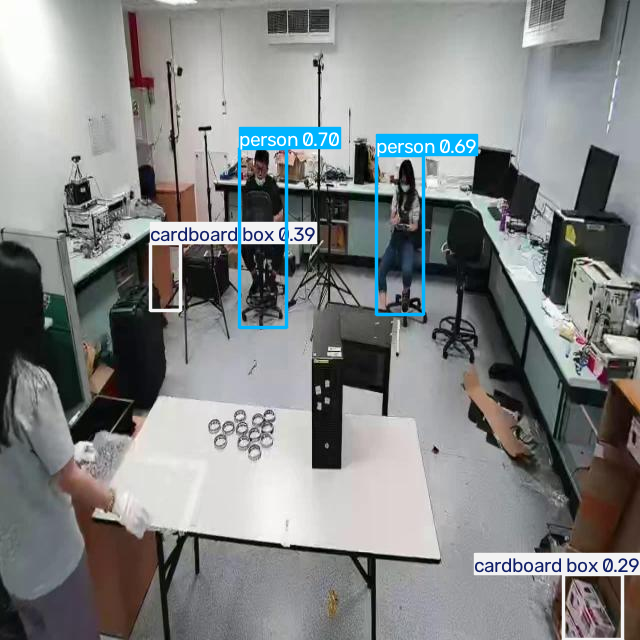

In [11]:
from PIL import Image as PILImage
display(PILImage.fromarray(results[0].plot()[..., ::-1]))

In [12]:
!pwd

/Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment


In [13]:
# Confianza baja para integrar la curva precisión–recall; 0.25 se usa en inferencia.
metrics = model.val(data=f"{dataset.location}/data.yaml", split="test", imgsz=640,
                    conf=0.001, batch=16, workers=0, device=DEVICE, plots=True,
                    project="runs/logistics", name="test", exist_ok=True)
report = {"model": "best.pt suministrado por el profesor", "dataset_version": 2,
          "validation": validation_metrics,
          "test": {"map50": float(metrics.box.map50), "map50_95": float(metrics.box.map),
                   "precision": float(metrics.box.mp), "recall": float(metrics.box.mr)},
          "download": json.loads((Path(dataset.location)/"download_complete.json").read_text())}
Path("evaluation_metrics.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
print(json.dumps(report, indent=2, ensure_ascii=False))

Ultralytics 8.4.174 🚀 Python-3.11.15 torch-2.14.1 MPS (Apple M4)


Model summary (fused): 72 layers, 3,009,548 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 149.9±42.5 MB/s, size: 66.9 KB)


val: Scanning /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/datasets/logistics_eval/test/labels... 1 images, 0 backgrounds, 0 corrupt: 0% ──────────── 1/9525 1.2s/it 0.4s<3:16:51

val: Scanning /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/datasets/logistics_eval/test/labels... 328 images, 0 backgrounds, 0 corrupt: 3% ──────────── 328/9525 968.7it/s 0.5s<9.5s

...

                   van        695        765      0.747      0.782      0.808      0.719


           wood pallet        689       9330      0.699      0.211       0.35      0.154


Speed: 0.5ms preprocess, 0.7ms inference, 0.0ms loss, 19.5ms postprocess per image


Results saved to /Users/fabiolavalencia/Documents/Codex/2026-10-06/bue/outputs/Talleres_IA/Semana_08/yolo/deployment/runs/detect/runs/logistics/test


{
  "model": "best.pt suministrado por el profesor",
  "dataset_version": 2,
  "validation": {
    "map50": 0.6332776959608134,
    "map50_95": 0.43281083389043395
  },
  "test": {
    "map50": 0.6268956454927738,
    "map50_95": 0.4296434238639607,
    "precision": 0.7091465298891249,
    "recall": 0.5848105395373622
  },
  "download": {
    "source": "large-benchmark-datasets/logistics-sz9jr/2",
    "selection": "All exported validation and test images, no train",
    "counts": {
      "valid": 18988,
      "test": 9525
    },
    "downloaded_bytes": 1556492792
  }
}


In [14]:
def encode_response(results):
    """
    Convert Ultralytics YOLO results (list of Results) into JSON-friendly dict.
    Uses class names from the results array itself.
    """
    detections = []
    if not results:
        return {"detections": detections}

    r = results[0]   # one Results object
    boxes = r.boxes

    if boxes is None or len(boxes) == 0:
        return {"detections": detections}

    cls = boxes.cls.cpu().numpy().astype(int)
    conf = boxes.conf.cpu().numpy()
    xyxy = boxes.xyxy.cpu().numpy()

    # names mapping is in the result object
    names = r.names  

    for class_id, confidence, bbox in zip(cls, conf, xyxy):
        detections.append({
            "class_id": int(class_id),
            "class_name": names[class_id],
            "confidence": float(confidence),
            "bbox": bbox.tolist()  # [x1, y1, x2, y2]
        })

    return {"detections": detections}

In [15]:
encode_response(results)

{'detections': [{'class_id': 10,
   'class_name': 'person',
   'confidence': 0.7011166214942932,
   'bbox': [239.93023681640625,
    148.03640747070312,
    286.88726806640625,
    327.0702819824219]},
  {'class_id': 10,
   'class_name': 'person',
   'confidence': 0.6905096173286438,
   'bbox': [376.00653076171875,
    155.86856079101562,
    423.67877197265625,
    314.604736328125]},
  {'class_id': 2,
   'class_name': 'cardboard box',
   'confidence': 0.39054179191589355,
   'bbox': [150.08480834960938,
    243.29476928710938,
    180.87603759765625,
    310.1686096191406]},
  {'class_id': 2,
   'class_name': 'cardboard box',
   'confidence': 0.2898879051208496,
   'bbox': [563.2796630859375,
    574.9051513671875,
    622.0970458984375,
    639.3233642578125]}]}

In [16]:
results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'barcode', 1: 'car', 2: 'cardboard box', 3: 'fire', 4: 'forklift', 5: 'freight container', 6: 'gloves', 7: 'helmet', 8: 'ladder', 9: 'license plate', 10: 'person', 11: 'qr code', 12: 'road sign', 13: 'safety vest', 14: 'smoke', 15: 'traffic cone', 16: 'traffic light', 17: 'truck', 18: 'van', 19: 'wood pallet'}
 obb: None
 orig_img: array([[[249, 254, 253],
         [249, 254, 253],
         [249, 254, 253],
         ...,
         [109, 107,  99],
         [109, 107,  99],
         [109, 107,  99]],
 
        [[249, 254, 253],
         [249, 254, 253],
         [249, 254, 253],
         ...,
         [109, 107,  99],
         [109, 107,  99],
         [109, 107,  99]],
 
        [[249, 254, 253],
         [249, 254, 253],
         [249, 254, 253],
         ...,
         [110, 108, 100],
         [110, 108, 100],
         [11

In [17]:
# Requiere iniciar server.py previamente.
# Desde terminal: python client.py --image RUTA_A_LA_IMAGEN

### Resultado y prueba del despliegue

Se evaluaron las 18.988 imágenes exportadas de validación y las 9.525 de test. En test: mAP50 = 0.6269, mAP50–95 = 0.4296, precisión = 0.7091 y recall = 0.5848. Se empleó confianza 0,001 para calcular la curva de evaluación; la inferencia del ejemplo utiliza 0,25.

La procedencia del entrenamiento original de `best.pt` no documenta aquí si vio estos datos; interpretar estas cifras como una evaluación del artefacto suministrado, no como una prueba independiente de generalización.

Se probó además `server.py` en localhost: el POST devolvió HTTP 200 y cuatro detecciones; `client.py` generó `example_input_annotated.jpg`. La respuesta se conserva en `example_response.json`. La imagen muestra detecciones de semáforos y alguna caja duplicada; no se afirma que todas sean correctas.

![Predicciones del servidor](example_input_annotated.jpg)

![Matriz de confusión de test](reports/test_confusion_matrix_normalized.png)